# Helsinki: daily-living destinations for the 15-minute city

Companion to `02.1`, which built the origin lattice and the door-to-door cost
matrices between hexagons. Population within reach is a destination layer that
needs no points of interest, but the 15-minute city asks a different question:
can the amenities of daily life be reached from home in a short trip without a
car? That needs the amenities themselves.

This notebook extracts them from the same OpenStreetMap release the networks
were built from, classifies them on two levels (a broad amenity category and a
finer class), and writes a destination layer the accessibility notebook can
route to.

| Step | Output |
|---|---|
| 1. Taxonomy | `poi_taxonomy.json`, the class rules as provenance |
| 2. Extraction | `pois.gpkg`, one point per amenity with its class and category |
| 3. Hexagon counts | `pois_per_hexagon.parquet`, amenities inside each lattice cell |
| 4. First look | Category and class counts, maps |

In [1]:
import json
import time
from pathlib import Path

import geopandas as gpd
import matplotlib.pyplot as plt
from matplotlib.ticker import MaxNLocator
import numpy as np
import pandas as pd
import pyrosm

import cafein.sampledata.helsinki as helsinki

## Parameters

The lattice and the results directory are the ones `02.1` produced. The
extraction extends beyond the inhabited lattice by a buffer so that hexagons on
the edge of the study area still see the amenities just outside it; 15 minutes
on foot is roughly 1.2 km.

In [2]:
CITY = "helsinki"
RESULTS = Path("/scratch/project_2010423/carbon-advantage") / CITY
METRIC_CRS = "EPSG:3067"

PARAMETERS = {
    "city": CITY,
    "osm_release": helsinki.metadata["osm_pbf"]["source_stamp"],
    # Extraction extent: the inhabited lattice plus this margin, in metres.
    "study_buffer_m": 1500,
    # Green areas smaller than this are dropped (pocket greens and traffic
    # islands are mapped as leisure=park too).
    "min_green_area_m2": 5000,
}

lattice = gpd.read_file(RESULTS / "lattice.gpkg")
study_area = (
    lattice.to_crs(METRIC_CRS).geometry.union_all().buffer(PARAMETERS["study_buffer_m"])
)
print(f"{len(lattice):,} hexagons, extraction extent {study_area.area / 1e6:,.0f} km²")

1,105 hexagons, extraction extent 1,054 km²


## 1. Taxonomy

The broad categories follow Zhang, Poliakov, Tenkanen and Arcaute (2025,
*Recurrent visitations expose the paradox of human mobility in the 15-Minute
City vision*, arXiv:2509.00919), whose ten-category scheme was synthesised from
the 15-minute city literature (Moreno et al. 2021; Abbiasov et al. 2024;
Papadopoulos et al. 2023; Bruno et al. 2024): civic and religion, culture,
dining, education, fitness, groceries, healthcare, retail, services and
transport. Their study classified a commercial point-of-interest product; here
the same categories are populated from OpenStreetMap tags, with their published
class-to-category assignment as the guide (library under civic, liquor stores
and opticians under retail, car repair and hairdressers under services).

Two departures. Green areas form an eleventh category, *park*, which Zhang et
al. mapped but left out of their ten and which the Nordic 15-minute literature
treats as essential. Parking lots are not a transport amenity here (they would
be the single largest class, and they are not a destination in the carbon
question), while stops, stations, city-bike racks and taxi stands are.

Each class is one rule over tags: a feature belongs when any listed key carries
one of the listed values. A feature matching several classes is kept once per
class. Any shop not claimed by a groceries, retail or services rule falls into
`other_retail`, except the values that are not a shop at all. The rules are
written next to the output as provenance, so a revised taxonomy only needs this
cell changed.

In [3]:
TAXONOMY = {
    # groceries
    "supermarket":      {"category": "groceries", "tags": {"shop": ["supermarket"]}},
    "convenience":      {"category": "groceries", "tags": {"shop": ["convenience", "kiosk", "grocery", "greengrocer", "deli", "frozen_food", "health_food", "dairy"]}},
    "bakery":           {"category": "groceries", "tags": {"shop": ["bakery", "pastry", "confectionery", "coffee", "tea", "chocolate"]}},
    "butcher_fish":     {"category": "groceries", "tags": {"shop": ["butcher", "seafood"]}},
    "marketplace":      {"category": "groceries", "tags": {"amenity": ["marketplace"]}},
    # dining
    "restaurant":       {"category": "dining", "tags": {"amenity": ["restaurant", "food_court"]}},
    "cafe":             {"category": "dining", "tags": {"amenity": ["cafe", "ice_cream"]}},
    "fast_food":        {"category": "dining", "tags": {"amenity": ["fast_food"]}},
    "nightlife":        {"category": "dining", "tags": {"amenity": ["bar", "pub", "nightclub", "biergarten"]}},
    # education
    "daycare":          {"category": "education", "tags": {"amenity": ["kindergarten", "childcare"]}},
    "school":           {"category": "education", "tags": {"amenity": ["school"]}},
    "higher_education": {"category": "education", "tags": {"amenity": ["college", "university"]}},
    "other_school":     {"category": "education", "tags": {"amenity": ["music_school", "language_school", "dancing_school"]}},
    # healthcare
    "pharmacy":         {"category": "healthcare", "tags": {"amenity": ["pharmacy"], "healthcare": ["pharmacy"]}},
    "doctor_clinic":    {"category": "healthcare", "tags": {"amenity": ["doctors", "clinic"], "healthcare": ["doctor", "clinic", "centre"]}},
    "hospital":         {"category": "healthcare", "tags": {"amenity": ["hospital"], "healthcare": ["hospital"]}},
    "dentist":          {"category": "healthcare", "tags": {"amenity": ["dentist"], "healthcare": ["dentist"]}},
    "therapy":          {"category": "healthcare", "tags": {"healthcare": ["physiotherapist", "psychotherapist", "alternative"]}},
    # fitness
    "fitness_centre":   {"category": "fitness", "tags": {"leisure": ["fitness_centre"]}},
    "sports_centre":    {"category": "fitness", "tags": {"leisure": ["sports_centre", "sports_hall", "ice_rink", "stadium"]}},
    "swimming":         {"category": "fitness", "tags": {"leisure": ["swimming_pool", "swimming_area", "bathing_place", "water_park"]}},
    "sports_field":     {"category": "fitness", "tags": {"leisure": ["pitch", "track", "fitness_station", "golf_course", "disc_golf_course", "horse_riding", "dance"]}},
    # culture
    "cinema":           {"category": "culture", "tags": {"amenity": ["cinema"]}},
    "theatre":          {"category": "culture", "tags": {"amenity": ["theatre", "arts_centre", "events_venue"]}},
    "museum_gallery":   {"category": "culture", "tags": {"tourism": ["museum", "gallery", "zoo", "aquarium"]}},
    "amusement":        {"category": "culture", "tags": {"leisure": ["bowling_alley", "amusement_arcade", "escape_game", "miniature_golf", "trampoline_park"], "tourism": ["theme_park"]}},
    # civic and religion
    "library":          {"category": "civic_religion", "tags": {"amenity": ["library"]}},
    "place_of_worship": {"category": "civic_religion", "tags": {"amenity": ["place_of_worship"]}},
    "community_centre": {"category": "civic_religion", "tags": {"amenity": ["community_centre", "youth_centre"]}},
    "public_office":    {"category": "civic_religion", "tags": {"amenity": ["townhall", "courthouse", "police"], "office": ["government"]}},
    # services
    "hairdresser":      {"category": "services", "tags": {"shop": ["hairdresser", "barber"]}},
    "beauty":           {"category": "services", "tags": {"shop": ["beauty", "massage", "tattoo", "nails"]}},
    "laundry":          {"category": "services", "tags": {"shop": ["laundry", "dry_cleaning"]}},
    "post_bank":        {"category": "services", "tags": {"amenity": ["post_office", "bank", "bureau_de_change"]}},
    "car_service":      {"category": "services", "tags": {"shop": ["car_repair", "car_wash", "tyres"], "amenity": ["fuel", "car_wash", "vehicle_inspection", "car_rental"]}},
    "repair":           {"category": "services", "tags": {"shop": ["tailor", "locksmith", "shoe_repair", "key_cutter", "repair", "electrical", "copyshop", "pet_grooming"], "craft": ["shoemaker", "dressmaker", "tailor", "electronics_repair", "upholsterer", "watchmaker"]}},
    "social_services":  {"category": "services", "tags": {"amenity": ["social_facility"]}},
    "veterinary":       {"category": "services", "tags": {"amenity": ["veterinary"]}},
    "travel_agency":    {"category": "services", "tags": {"shop": ["travel_agency"]}},
    # retail
    "shopping_centre":  {"category": "retail", "tags": {"shop": ["mall", "department_store"]}},
    "clothing":         {"category": "retail", "tags": {"shop": ["clothes", "shoes", "bag", "boutique", "fashion_accessories", "second_hand", "charity", "baby_goods"]}},
    "home_hardware":    {"category": "retail", "tags": {"shop": ["furniture", "interior_decoration", "kitchen", "houseware", "bed", "curtain", "lighting", "hardware", "doityourself", "garden_centre", "paint", "flooring", "bathroom_furnishing", "carpet", "appliance"]}},
    "electronics":      {"category": "retail", "tags": {"shop": ["electronics", "computer", "mobile_phone", "hifi", "photo", "video_games", "telecommunication"]}},
    "books_hobby":      {"category": "retail", "tags": {"shop": ["books", "stationery", "gift", "toys", "art", "music", "musical_instrument", "craft", "fabric", "sewing", "antiques", "games", "model", "video", "newsagent"]}},
    "sports_outdoor":   {"category": "retail", "tags": {"shop": ["sports", "outdoor", "bicycle", "fishing", "hunting"]}},
    "jewelry_optician": {"category": "retail", "tags": {"shop": ["jewelry", "watches", "optician"]}},
    "chemist":          {"category": "retail", "tags": {"shop": ["chemist", "cosmetics", "perfumery", "medical_supply", "hearing_aids"]}},
    "florist_pet":      {"category": "retail", "tags": {"shop": ["florist", "pet"]}},
    "alcohol":          {"category": "retail", "tags": {"shop": ["alcohol", "wine"]}},
    "car_dealer":       {"category": "retail", "tags": {"shop": ["car", "car_parts", "motorcycle"]}},
    "other_retail":     {"category": "retail", "tags": {"shop": "*"}},
    # transport
    "bus_stop":         {"category": "transport", "tags": {"highway": ["bus_stop"], "amenity": ["bus_station"]}},
    "tram_stop":        {"category": "transport", "tags": {"railway": ["tram_stop"]}},
    "rail_station":     {"category": "transport", "tags": {"railway": ["station", "halt"]}},
    "ferry_terminal":   {"category": "transport", "tags": {"amenity": ["ferry_terminal"]}},
    "bike_share":       {"category": "transport", "tags": {"amenity": ["bicycle_rental"]}},
    "taxi":             {"category": "transport", "tags": {"amenity": ["taxi"]}},
    # park (outside the ten categories of Zhang et al.)
    "park":             {"category": "park", "tags": {"leisure": ["park", "garden"]}, "min_area_m2": "min_green_area_m2"},
    "nature_reserve":   {"category": "park", "tags": {"leisure": ["nature_reserve"]}, "min_area_m2": "min_green_area_m2"},
    "playground":       {"category": "park", "tags": {"leisure": ["playground"]}},
    "dog_park":         {"category": "park", "tags": {"leisure": ["dog_park"]}},
}

# shop=* values that are not a shop a resident visits.
NOT_A_SHOP = ["yes", "no", "vacant", "storage_rental", "wholesale", "empty", "disused"]

CATEGORIES = list(dict.fromkeys(rule["category"] for rule in TAXONOMY.values()))
CLASSES = list(TAXONOMY)

(RESULTS / "poi_taxonomy.json").write_text(
    json.dumps({"parameters": PARAMETERS, "not_a_shop": NOT_A_SHOP, "taxonomy": TAXONOMY}, indent=2)
)
print(f"{len(CLASSES)} classes in {len(CATEGORIES)} categories: {', '.join(CATEGORIES)}")

61 classes in 11 categories: groceries, dining, education, healthcare, fitness, culture, civic_religion, services, retail, transport, park


## 2. Extraction

One pass over the PBF with the union of every rule's tags. pyrosm exposes the
common keys as columns and keeps the rest in a JSON `tags` column
(`healthcare=*` lives there), so both are consulted. Amenities mapped as
building footprints or green polygons become their centroid.

In [4]:
def union_filter(taxonomy):
    '''The pyrosm custom filter selecting every tag any class uses; a
    wildcard rule selects every value of its key.'''
    keys = {}
    for rule in taxonomy.values():
        for key, values in rule["tags"].items():
            if values == "*" or keys.get(key) is True:
                keys[key] = True
            else:
                keys.setdefault(key, set()).update(values)
    return {key: (True if values is True else sorted(values)) for key, values in keys.items()}


def tag_values(frame, key):
    '''One Series of a tag's values, from the column when pyrosm exposes
    it and from the JSON tags otherwise.'''
    from_json = frame["_tags"].map(lambda tags: tags.get(key))
    if key in frame.columns:
        return frame[key].where(frame[key].notna(), from_json)
    return from_json


started = time.time()
osm = pyrosm.OSM(str(helsinki.osm_pbf))
raw = osm.get_pois(custom_filter=union_filter(TAXONOMY))
raw["_tags"] = raw["tags"].map(lambda value: json.loads(value) if isinstance(value, str) else {})
raw = raw.to_crs(METRIC_CRS)
raw["area_m2"] = raw.geometry.area
print(f"{len(raw):,} candidate features in {time.time() - started:.0f} s")

# Values an explicit rule claims, per key, so a wildcard rule takes the rest.
claimed = {}
for rule in TAXONOMY.values():
    for key, values in rule["tags"].items():
        if values != "*":
            claimed.setdefault(key, set()).update(values)

rows = []
for poi_class, rule in TAXONOMY.items():
    matches = np.zeros(len(raw), dtype=bool)
    for key, values in rule["tags"].items():
        present = tag_values(raw, key)
        if values == "*":
            matches |= (present.notna() & ~present.isin(claimed[key]) & ~present.isin(NOT_A_SHOP)).to_numpy()
        else:
            matches |= present.isin(values).to_numpy()
    if "min_area_m2" in rule:
        matches &= (raw["area_m2"] >= PARAMETERS[rule["min_area_m2"]]).to_numpy()
    selected = raw.loc[matches]
    rows.append(
        gpd.GeoDataFrame(
            {
                "osm_type": selected["osm_type"].to_numpy(),
                "osm_id": selected["id"].astype("int64").to_numpy(),
                "name": selected["name"].to_numpy(),
                "poi_class": poi_class,
                "category": rule["category"],
                "area_m2": selected["area_m2"].to_numpy(),
            },
            geometry=selected.geometry.centroid.to_numpy(),
            crs=METRIC_CRS,
        )
    )

pois = pd.concat(rows, ignore_index=True)
pois = pois.drop_duplicates(["osm_type", "osm_id", "poi_class"])
pois = pois.loc[pois.within(study_area)].reset_index(drop=True)
pois["poi_class"] = pd.Categorical(pois["poi_class"], categories=CLASSES)
pois["category"] = pd.Categorical(pois["category"], categories=CATEGORIES)

pois.to_crs("EPSG:4326").to_file(RESULTS / "pois.gpkg", layer="pois", driver="GPKG")
print(f"{len(pois):,} amenities in the study area")
pois["category"].value_counts(sort=False).to_frame("amenities")

36,886 candidate features in 14 s


31,083 amenities in the study area


,amenities
category,
groceries,921
dining,3581
education,1418
healthcare,501
fitness,3866
culture,454
civic_religion,700
services,3011
retail,2976


Which shop values the wildcard rule swept into `other_retail`, as a check
that nothing a class should claim is hiding there.

In [5]:
other = raw.loc[raw["id"].isin(pois.loc[pois["poi_class"] == "other_retail", "osm_id"])]
tag_values(other, "shop").value_counts().head(25).to_frame("features")

,features
shop,
variety_store,45
funeral_directors,28
ticket,23
rental,14
trade,12
pawnbroker,12
frame,12
tobacco,11
party,10


## 3. Amenities per hexagon

A point-in-polygon count per lattice cell, by class and by category. This is
not yet an accessibility measure (an amenity across the hexagon boundary
counts for nothing here), but it is the quickest check that the extraction
covers the region sensibly, and a convenient join for descriptive tables.

In [6]:
joined = gpd.sjoin(
    pois[["poi_class", "category", "geometry"]],
    lattice.to_crs(METRIC_CRS)[["id", "geometry"]],
    how="inner",
    predicate="within",
)
per_hexagon = (
    joined.groupby(["id", "category", "poi_class"], observed=True).size()
    .rename("count").reset_index()
)
per_hexagon.to_parquet(RESULTS / "pois_per_hexagon.parquet", index=False)

category_wide = (
    per_hexagon.groupby(["id", "category"], observed=False)["count"].sum().unstack(fill_value=0)
    .reindex(lattice["id"], fill_value=0)
)
population = lattice.set_index("id")["population"]
summary = pd.DataFrame(
    {
        "amenities": pois["category"].value_counts(sort=False),
        "classes": pois.groupby("category", observed=False)["poi_class"].nunique(),
        "hexagons_with_one": (category_wide > 0).sum(),
        "population_share_with_one": (
            (category_wide > 0).mul(population, axis=0).sum() / population.sum()
        ).round(2),
    }
)
summary

,amenities,classes,hexagons_with_one,population_share_with_one
category,,,,
groceries,921,5,313,0.64
dining,3581,4,439,0.73
education,1418,4,488,0.82
healthcare,501,5,169,0.44
fitness,3866,4,735,0.91
culture,454,4,156,0.30
civic_religion,700,4,286,0.57
services,3011,9,458,0.75
retail,2976,12,349,0.59


In [7]:
classes = (
    pois.groupby(["category", "poi_class"], observed=True).size().rename("amenities").reset_index()
)
classes["hexagons_with_one"] = classes["poi_class"].map(
    per_hexagon.groupby("poi_class", observed=True)["id"].nunique()
).fillna(0).astype(int)
pd.set_option("display.max_rows", 100)
classes.set_index(["category", "poi_class"])

amenities  hexagons_with_one
category       poi_class                                     
groceries      supermarket             201                125
               convenience             544                240
               bakery                  136                 69
               butcher_fish             27                 13
               marketplace              13                  9
dining         restaurant             1831                329
               cafe                    691                191
               fast_food               521                192
               nightlife               538                153
education      daycare                 872                408
               school                  459                294
               higher_education         47                 33
               other_school             40                 35
healthcare     pharmacy                114                 89
               doctor_clinic           158                 83
               hospital                 36                 30
               dentist                 116                 72
               therapy                  77                 51
fitness        fitness_centre          227                139
               sports_centre           381                196
               swimming                380                211
               sports_field           2878                639
culture        cinema                   28                 22
               theatre                 192                 90
               museum_gallery          178                 73
               amusement                56                 46
civic_religion library                  95                 78
               place_of_worship        213                144
               community_centre        252                174
               public_office           140                 55
services       hairdresser             900                200
               beauty                  624                144
               laundry                  67                 48
               post_bank               100                 47
               car_service             690                232
               repair                  190                 98
               social_services         362                199
               veterinary               61                 53
               travel_agency            17                 11
retail         shopping_centre          85                 61
               clothing                649                106
               home_hardware           459                137
               electronics             176                 66
               books_hobby             312                 83
               sports_outdoor          188                101
               jewelry_optician        219                 49
               chemist                  80                 31
               florist_pet             150                 92
               alcohol                  60                 52
               car_dealer              169                 66
               other_retail            429                167
transport      bus_stop               6291                877
               tram_stop               365                 48
               rail_station            104                 89
               ferry_terminal           76                 26
               bike_share              556                314
               taxi                    131                100
park           park                   1305                578
               nature_reserve          256                125
               playground             4368                650
               dog_park                203                145

## 4. First look

Counts per category and per class, and where the amenities sit on the lattice.
The maps show the in-hexagon counts from step 3, classed by natural breaks
separately for every category, so each panel reads on its own scale.

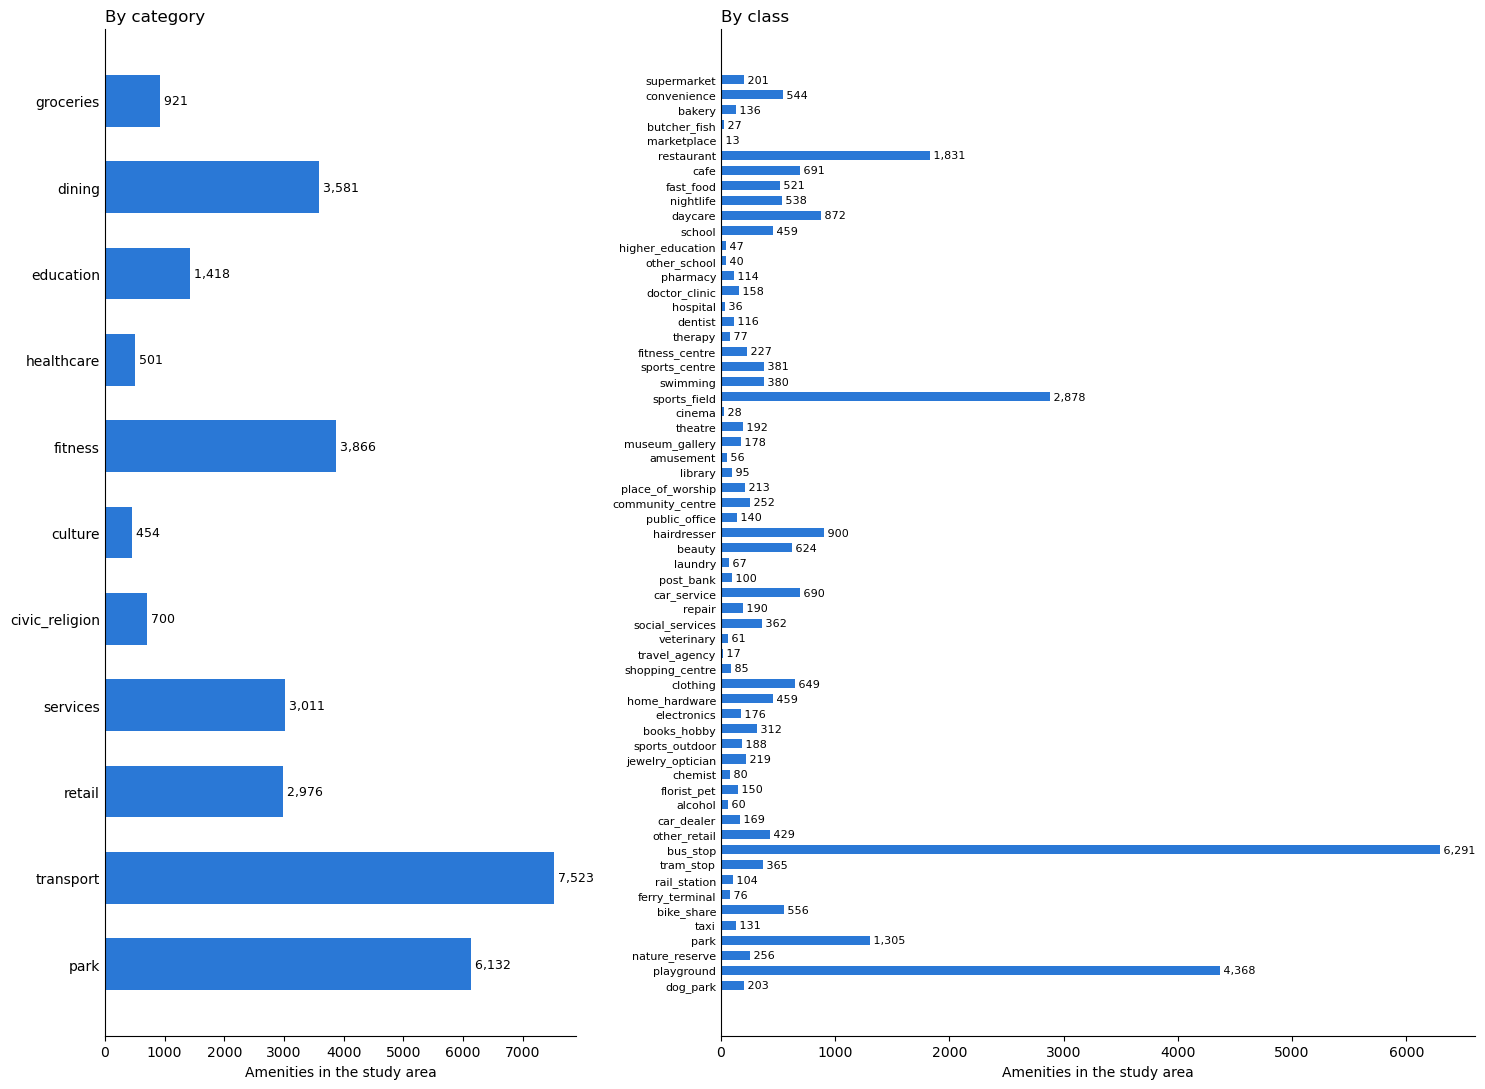

In [8]:
figure, axes = plt.subplots(ncols=2, figsize=(15, 11), gridspec_kw={"width_ratios": [1, 1.6]})

counts = summary["amenities"].iloc[::-1]
axes[0].barh(counts.index.astype(str), counts.to_numpy(), color="#2a78d6", height=0.6)
for position, value in enumerate(counts.to_numpy()):
    axes[0].text(value, position, f" {value:,}", va="center", fontsize=9)
axes[0].set_xlabel("Amenities in the study area")
axes[0].set_title("By category", loc="left")

ordered = classes.set_index("poi_class")["amenities"].iloc[::-1]
axes[1].barh(ordered.index.astype(str), ordered.to_numpy(), color="#2a78d6", height=0.6)
for position, value in enumerate(ordered.to_numpy()):
    axes[1].text(value, position, f" {value:,}", va="center", fontsize=8)
axes[1].set_xlabel("Amenities in the study area")
axes[1].set_title("By class", loc="left")
axes[1].tick_params(axis="y", labelsize=8)

for axis in axes:
    axis.spines[["top", "right"]].set_visible(False)
    axis.tick_params(axis="y", length=0)
figure.tight_layout()

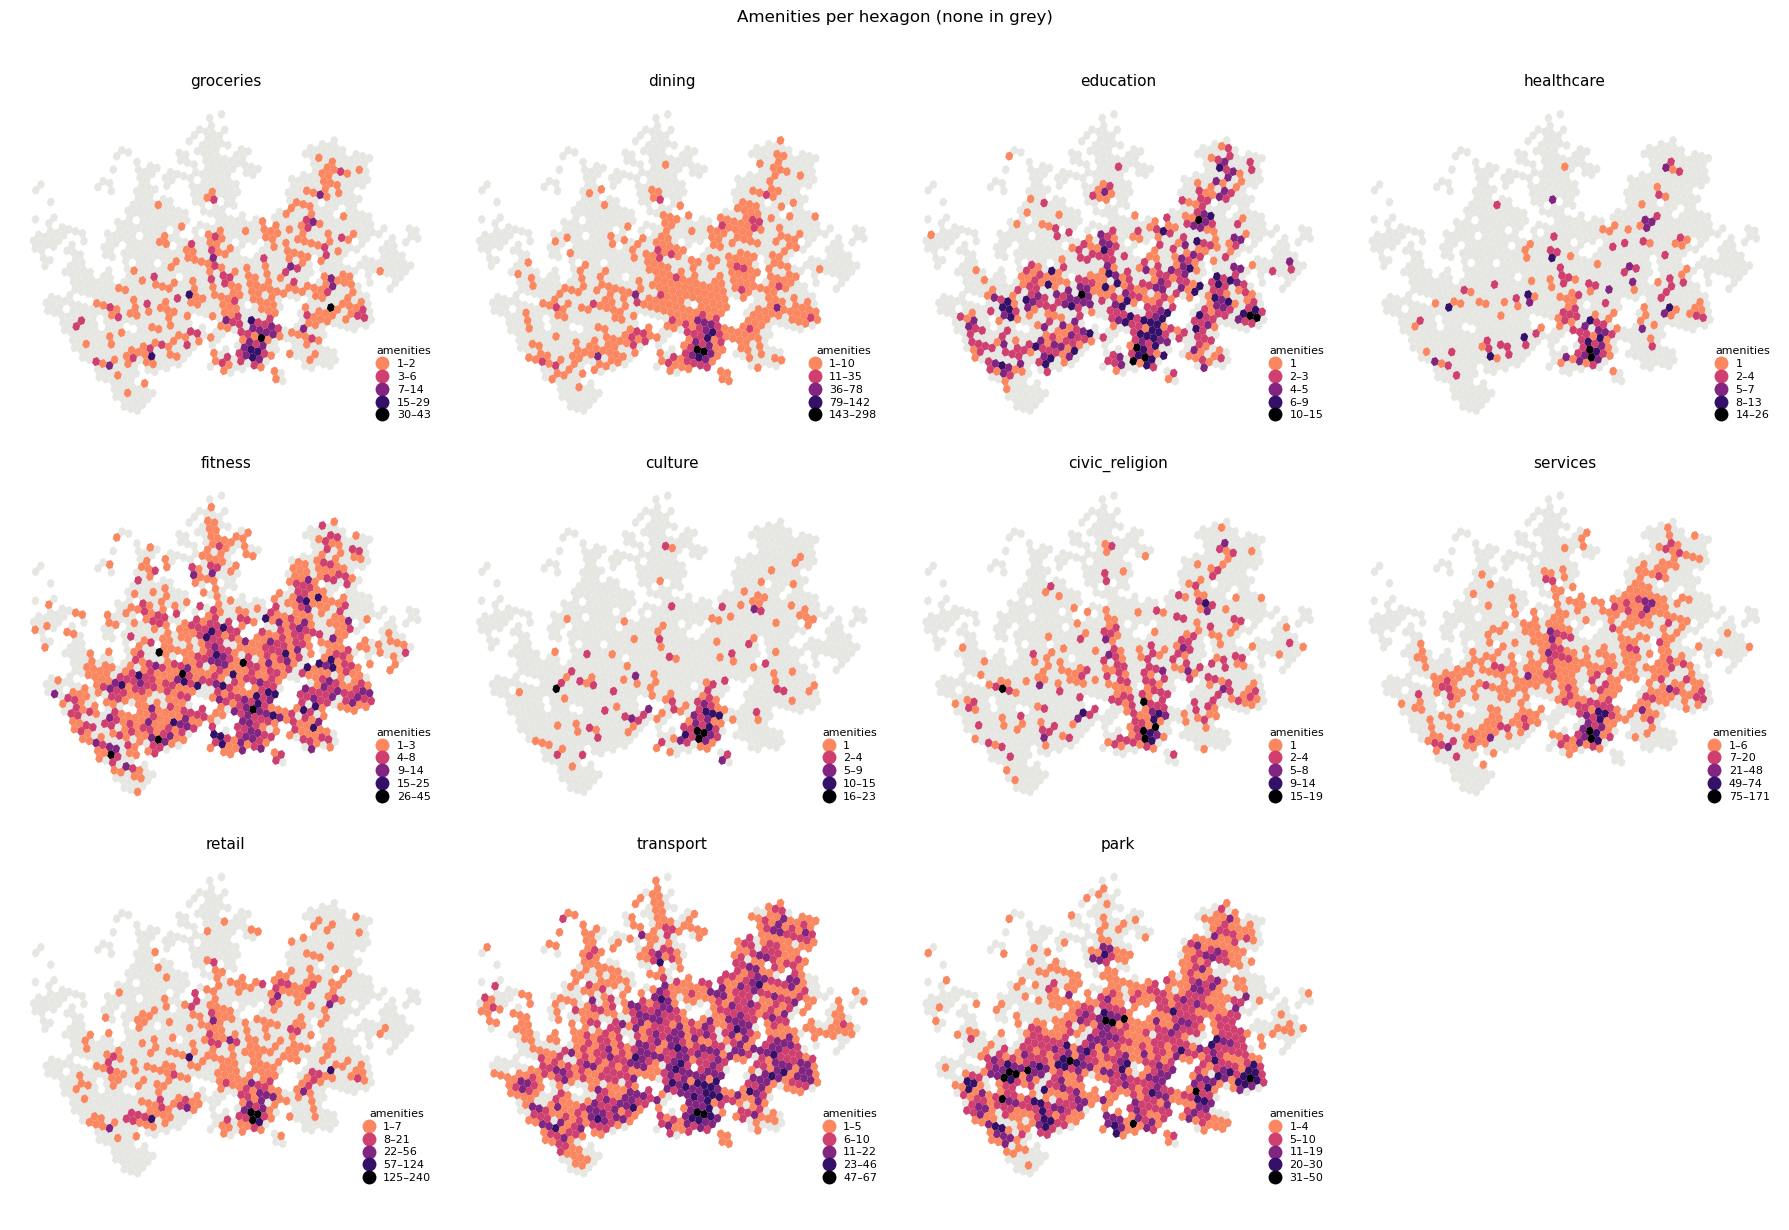

In [9]:
import mapclassify
from matplotlib.colors import ListedColormap


def class_labels(bins, lowest):
    '''Integer range per class from a classifier's upper bounds.'''
    labels, low = [], int(lowest)
    for high in bins:
        high = int(high)
        labels.append(f"{low}" if low == high else f"{low}–{high}")
        low = high + 1
    return labels


lattice_metric = lattice.to_crs(METRIC_CRS).set_index("id")
palette = plt.get_cmap("magma_r")
figure, axes = plt.subplots(nrows=3, ncols=4, figsize=(18, 12.5))
for axis, category in zip(axes.ravel(), CATEGORIES):
    frame = lattice_metric.assign(count=category_wide[category])
    with_amenity = frame.loc[frame["count"] > 0]
    # Five natural-breaks classes, fitted to each category on its own; the
    # palette skips the near-white end so the lowest class stands off the
    # grey of the empty hexagons.
    k = min(5, with_amenity["count"].nunique())
    classifier = mapclassify.NaturalBreaks(with_amenity["count"].to_numpy(), k=k)
    frame.plot(ax=axis, color="#e6e6e3", linewidth=0)
    with_amenity.assign(bin=classifier.yb).plot(
        ax=axis, column="bin", categorical=True, cmap=ListedColormap(palette(np.linspace(0.25, 1.0, k))),
        linewidth=0, legend=True,
        legend_kwds={"loc": "lower right", "fontsize": 8, "title": "amenities", "title_fontsize": 8,
                     "frameon": False, "labelspacing": 0.25, "handlelength": 1.0},
    )
    for text, label in zip(axis.get_legend().get_texts(), class_labels(classifier.bins, with_amenity["count"].min())):
        text.set_text(label)
    axis.set_title(category, fontsize=11)
for axis in axes.ravel():
    axis.set_axis_off()
figure.suptitle("Amenities per hexagon (none in grey)")
figure.tight_layout(rect=(0, 0, 1, 0.97))

## Next

- Reach to the nearest amenity of each class from every hexagon on foot and by
  bicycle, over the street artifact from `02.1`, and by transit; the 15-minute
  score per hexagon is then the number of categories (or classes) within the
  budget, and the carbon question becomes which of them a household can only
  reach within budget by car.
- Open points: a workplace layer for the working function (no point-of-interest
  form; a workplace grid); the green rule (centroid of a large polygon
  understates the reach of a park that a street passes along); sauna, garden
  and private sports facilities are left out although OSM maps thousands.